In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
model = tf.keras.applications.resnet_v2.ResNet50V2(include_top=True,weights='imagenet')
model.trainable = False
decode_predictions = tf.keras.applications.resnet_v2.decode_predictions

102869336/102869336 [==============================] - 1s 0us/step


In [ ]:
def preprocess(image):
    img = tf.keras.preprocessing.image.load_img(image, target_size=(224, 224))
    img = tf.keras.preprocessing.image.img_to_array(img)
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.resnet_v2.preprocess_input(img)
    img = img[None,...]
    return img

In [ ]:
img = 'cat2.jpg'
img = preprocess(img)

pred = model.predict(img)
lab = decode_predictions(pred,top=1)[0][0][1]
conf = decode_predictions(pred,top=1)[0][0][2]
print(lab)
print(conf*100)
print('Index of label = {}'.format(pred.argmax()))

35363/35363 [==============================] - 0s 0us/step
Egyptian_cat
42.539823055267334
Index of label = 285


<function matplotlib.pyplot.show(close=None, block=None)>

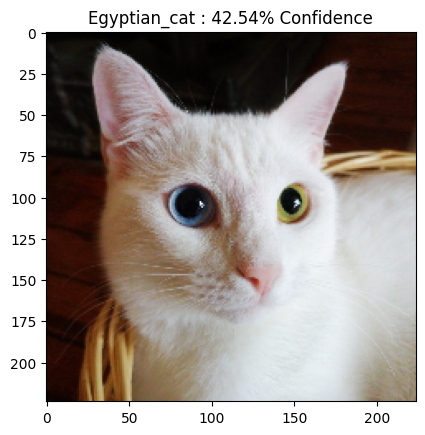

In [ ]:
plt.imshow(tf.keras.preprocessing.image.load_img('cat2.jpg', target_size=(224, 224)))
plt.title('{} : {:.2f}% Confidence'.format(lab, conf*100))
plt.show

In [ ]:
loss_object = tf.keras.losses.CategoricalCrossentropy()

def get_adversarial_pattern(input_image, input_label):
  with tf.GradientTape() as tape:
    tape.watch(input_image)
    prediction = model(input_image)
    loss = loss_object(input_label, prediction)

  # Get the gradients of the loss w.r.t to the input image.
  gradient = tape.gradient(loss, input_image)
  # Get the sign of the gradients to create the perturbation
  signed_grad = tf.sign(gradient)
  return signed_grad

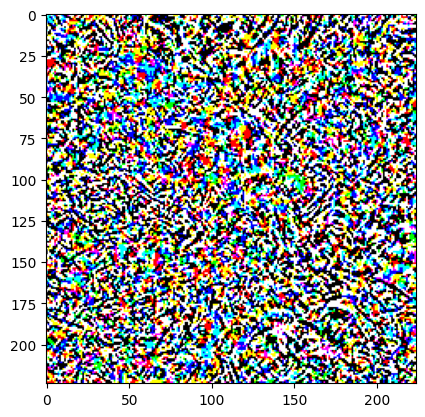

In [ ]:
# Get the input label of the image.
label_index = pred.argmax()
label = tf.one_hot(label_index, pred.shape[-1])
label = tf.reshape(label, (1, pred.shape[-1]))

perturbations = get_adversarial_pattern(img, label)
plt.imshow(perturbations[0] * 0.5 + 0.5);  # To change [-1, 1] to [0,1]

In [ ]:
def display_images(image, description):
  pred = model.predict(image)
  lab = decode_predictions(pred,top=1)[0][0][1]
  conf = decode_predictions(pred,top=1)[0][0][2]
  plt.figure()
  plt.imshow(image[0]*0.5+0.5)
  plt.title('{} \n {} : {:.4f}% Confidence'.format(description, lab, conf*100))
  plt.show()
  return conf*100,lab

1/1 [==============================] - 0s 193ms/step


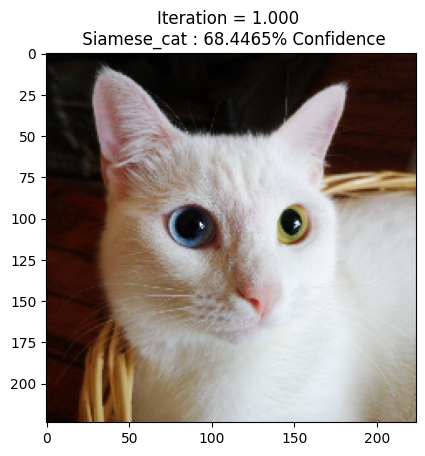

1/1 [==============================] - 0s 330ms/step


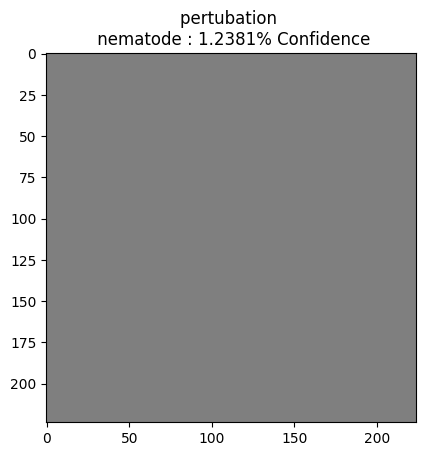

1/1 [==============================] - 0s 192ms/step


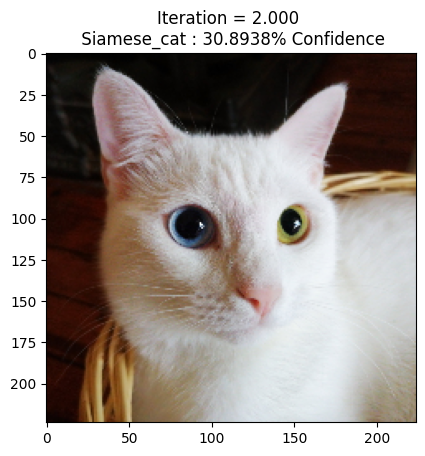

1/1 [==============================] - 0s 215ms/step


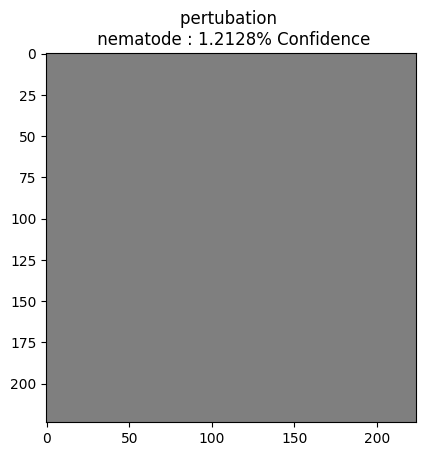

1/1 [==============================] - 0s 188ms/step


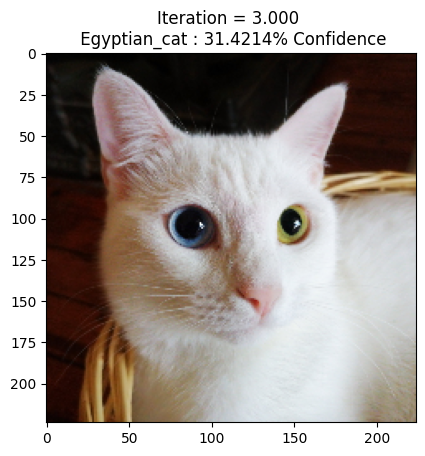

1/1 [==============================] - 0s 204ms/step


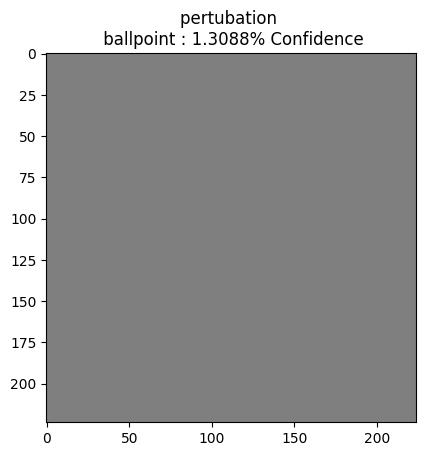

1/1 [==============================] - 0s 200ms/step


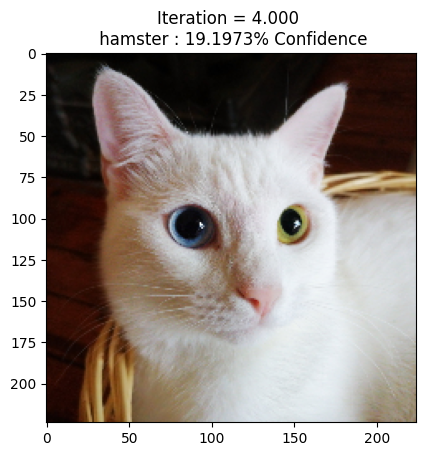

1/1 [==============================] - 0s 187ms/step


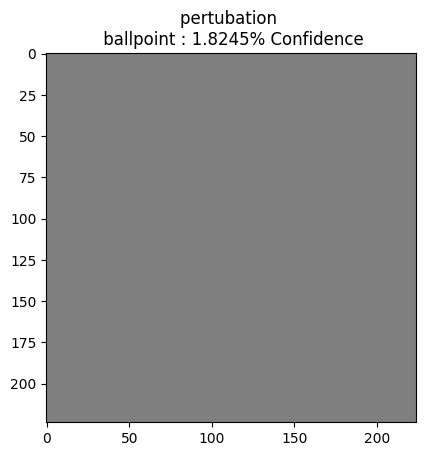

1/1 [==============================] - 0s 194ms/step


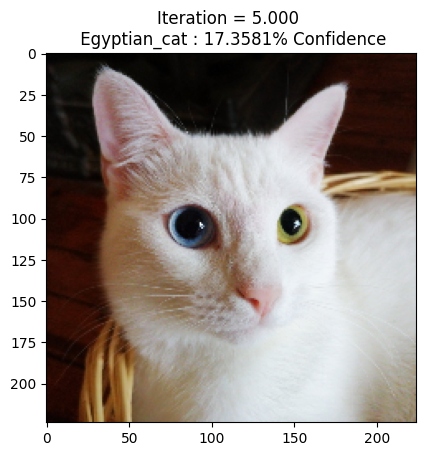

1/1 [==============================] - 0s 220ms/step


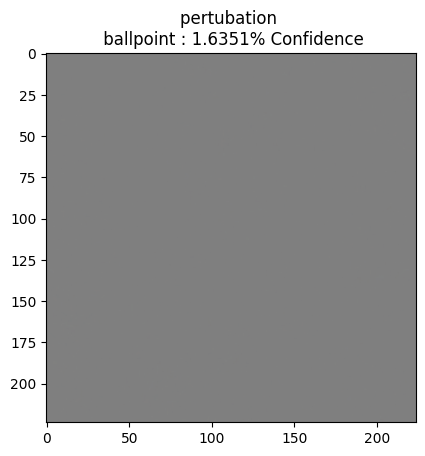

1/1 [==============================] - 0s 291ms/step


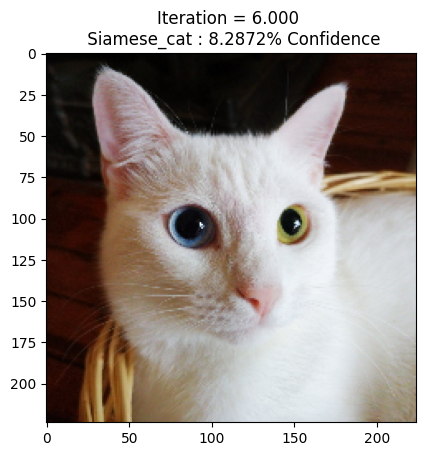

1/1 [==============================] - 0s 204ms/step


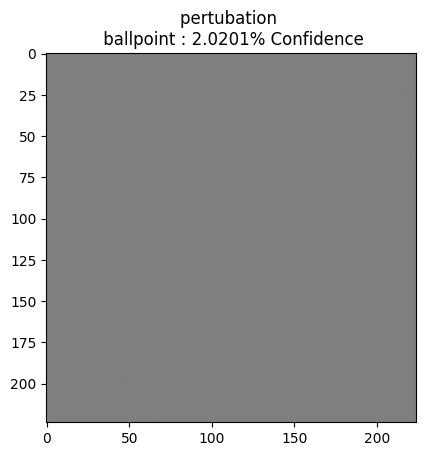

[{'Siamese_cat': 68.4464693069458, 'nematode': 1.2380757369101048}, {'Siamese_cat': 30.893811583518982, 'nematode': 1.2128479778766632}, {'Egyptian_cat': 31.42141103744507, 'ballpoint': 1.3087916187942028}, {'hamster': 19.197259843349457, 'ballpoint': 1.8244609236717224}, {'Egyptian_cat': 17.358098924160004, 'ballpoint': 1.6350794583559036}, {'Siamese_cat': 8.287239819765091, 'ballpoint': 2.020064741373062}]


In [ ]:
adv_x = img
eps = 0.005
t = 6
alpha = eps/t
descriptions = [('Iteration = {:0.3f}'.format(i+1)) for i in range(0,1000)]

ans=[]

for i in range(0,t):
  result={}
  #current prediction
  pred = model.predict(adv_x)

  #getting label of true class
  label_index = pred.argmax()
  label = tf.one_hot(label_index, pred.shape[-1])
  label = tf.reshape(label, (1, pred.shape[-1]))

  #creating pertubations for t timestamp
  perturbations = get_adversarial_pattern(adv_x, label)

  #updating our adversarial examples for t timestamp
  adv_x = adv_x + alpha*perturbations
  adv_x = tf.clip_by_value(adv_x, -1, 1)

  #displaying final adversarial example
  conf1,lab1=display_images(adv_x, descriptions[i])
  conf2,lab2=display_images(adv_x - img, 'pertubation')
  result[lab1]=conf1
  result[lab2]=conf2
  ans.append(result)
print(ans)

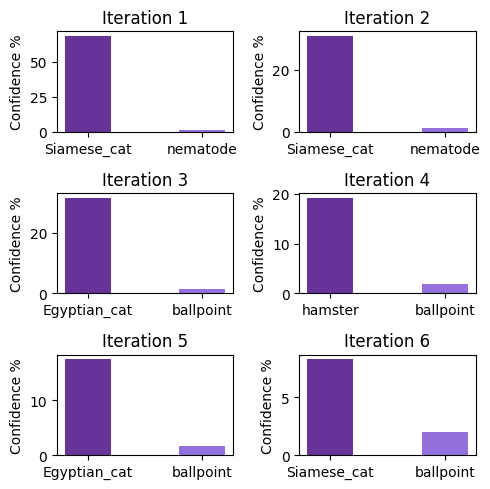

In [ ]:
# Create a 2x2 figure
fig, axs = plt.subplots(3, 2, figsize=(5,5))

# Define colors
colors = ['rebeccapurple', 'mediumpurple']

# Plot data from each dictionary
for i, data_dict in enumerate(ans):
    row = i // 2
    col = i % 2
    ax = axs[row, col]

    labels = list(data_dict.keys())
    values = list(data_dict.values())

    # Define a width for the bars
    width = 0.4

    x = np.arange(len(labels))

    ax.bar(x, values, width=width, color=colors)

    ax.set_title(f'Iteration {i + 1}')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel('Confidence %')

# Adjust layout
plt.tight_layout()

# Show the combined figure
plt.show()